In [1]:
import numpy as np

import sympy as sp

from sympy import sin
import time
import math

from utils import ( 
        get_fitted_scaler_from_csv, 
        clean_point, 
        symbolic_gradient, 
        mean_absolute_error_numpy, 
        get_distances_and_features_ckdtree,
        calculate_weight_matrix,
        predict_gibbs_energy_arrays,
        get_neighbors,
        COLUMN_TO_VAR
)
from scipy.spatial import cKDTree

# Example usage
file_path = "/home/couchbucks/Documents/saketh/regression/regression/718_all/718_all.csv"
target_col = 'Gibbs_energy'
x_scaler, y_scaler, scaled_df = get_fitted_scaler_from_csv(file_path, target_col, scale_data=True)

_, _, true_df = get_fitted_scaler_from_csv(file_path, target_col, scale_data=False)


# Calculate the number of rows to sample (80% of the DataFrame)
sample_size = int(len(scaled_df) * 0.8)

# Randomly sample 80% of the rows
reference_df = scaled_df.sample(n=sample_size, random_state=42)

# Specify the new order of columns
new_order = [
    'Temperature_[K]',
    'Mass_fraction_Nb',
    'Mass_fraction_Al',
    'Mass_fraction_Ti',
    'Mass_fraction_Mo',
    'Mass_fraction_Fe',
    'Mass_fraction_Cr',
    # 'Mass_fraction_Ni'
]


ref_gibbs = np.array(reference_df['Gibbs_energy'])

reference_df_rename = reference_df[new_order].rename(columns=COLUMN_TO_VAR)

df_reset_ref = reference_df_rename.reset_index(drop=True)

# Convert the DataFrame to a NumPy array
ref_points = np.array([clean_point(point) for point in df_reset_ref.values])


sampled_indices = reference_df.index

# Select the remaining 20% of the rows that were not sampled
remaining_df = scaled_df.drop(sampled_indices)

test_gibbs = np.array(remaining_df['Gibbs_energy'])

# Rename columns and reorder for consistency
remaining_df = remaining_df[new_order].rename(columns=COLUMN_TO_VAR)

df_reset = remaining_df.reset_index(drop=True)

# Convert the DataFrame to a NumPy array
query_points = np.array([clean_point(point) for point in df_reset.values])

# Function to compute the symbolic gradient of an expression with respect to each variable

x0, x1, x2, x3, x4, x5, x6 = sp.symbols('x0 x1 x2 x3 x4 x5 x6')
filter_variables = [x0, x1, x2, x3, x4, x5, x6]


relevant_variables = [x0, x1, x2, x3, x4, x5, x6]

# 0.00041702 ± 0.00228150
SIMPLIFIED_EQS = {
    'nb': 1.0327**(x0 - 0.1473) * (-x0 + 0.0214 * x1**2 - 0.0892 * x1 + 0.0117),
    'al': 0.1710 * 0.4880**x2 - 0.951 * x0 - 0.0346 * x0**2 + 0.0132 * x0 * x2 - 0.0012 * x2**2 - 0.414,
    'ti': -x0 + 0.244 * (0.5498**x3 - 1.0615),
    'mo': -x0 - 0.0321 * x0**2 + 0.0321 * sin(x4) + 0.0487,
    'fe': 1.0334572**x0 * (-x0),  # Simplified with assumptions
    # 'fe': -x0 + 0.0323 * x0**2 + 0.00302 * x0 * x5 + 0.00086 * x5**2 - 0.0323 * exp(-0.1797 * x5),
    # 'cr': -x0 - x0**2 * 0.0323 + x6 * sin(sin(0.8701099**(x0 - x6))) * 0.0323 + 0.0305
    'cr': -x0 - 0.03286*x0**2 - 0.0241007*(-0.04523*x6**2 - x6) + 0.032916
}

EVEN_MORE_SIMPLIFIED_EQS = {
    'nb': 1.03 * (-x0 + 0.0214 * x1**2 - 0.089 * x1 + 0.0117),
    'al': 0.171 * 0.5**x2 - x0 - 0.035 * x0**2 + 0.013 * x0 * x2 - 0.0012 * x2**2 - 0.414,
    'ti': -x0 + 0.244 * (0.55**x3 - 1.06),
    'mo': -x0 - 0.032 * x0**2 + 0.032 * sin(x4) + 0.05,
    'fe': 1.03* (-x0),  # Simplified with assumptions
    # 'fe': -x0 + 0.0323 * x0**2 + 0.00302 * x0 * x5 + 0.00086 * x5**2 - 0.0323 * exp(-0.1797 * x5),
    # 'cr': -x0 - x0**2 * 0.0323 + x6 * sin(sin(0.8701099**(x0 - x6))) * 0.0323 + 0.0305
    'cr': -x0 - 0.033*x0**2 - 0.024*(-0.045*x6**2 - x6) + 0.033
}

EVEN_EVEN_MORE_SIMPLIFIED_EQS = {
    'nb': -x0 + 0.021 * x1**2 - 0.089 * x1 + 0.012,
    'al': 0.17 * 0.5**x2 - x0 - 0.035 * x0**2 + 0.013 * x0 * x2 - 0.001 * x2**2 - sp.sqrt(2),
    'ti': -x0 + 0.244 * (0.5**x3 - 1),
    'mo': -x0 - 0.032 * x0**2 + 0.032 * sin(x4) + 0.05,
    'fe': -x0,  # Simplified with assumptions
    # 'fe': -x0 + 0.0323 * x0**2 + 0.00302 * x0 * x5 + 0.00086 * x5**2 - 0.0323 * exp(-0.1797 * x5),
    # 'cr': -x0 - x0**2 * 0.0323 + x6 * sin(sin(0.8701099**(x0 - x6))) * 0.0323 + 0.0305
    'cr': -x0 - 0.033*x0**2 - 0.025*(-0.045*x6**2 - x6) + 0.033
}

EVEN_EVEN_EVEN_MORE_SIMPLIFIED_EQS = {
    'nb': -x0 + 0.02 * x1**2 - 0.09 * x1 + 0.01,
    'al': 0.17 * 0.5**x2 - x0 - 0.04 * x0**2 + 0.01 * x0 * x2 - 0.001 * x2**2 - sp.sqrt(2),
    'ti': -x0 + 0.25 * (0.5**x3 - 1),
    'mo': -x0 - 0.03 * x0**2 + 0.03 * sin(x4) + 0.05,
    'fe': -x0,  # Simplified with assumptions
    # 'fe': -x0 + 0.0323 * x0**2 + 0.00302 * x0 * x5 + 0.00086 * x5**2 - 0.0323 * exp(-0.1797 * x5),
    # 'cr': -x0 - x0**2 * 0.0323 + x6 * sin(sin(0.8701099**(x0 - x6))) * 0.0323 + 0.0305
    'cr': -x0 - 0.03*x0**2 - 0.03*(-0.05*x6**2 - x6) + 0.03
}

EVEN_EVEN_EVEN_EVEN_MORE_SIMPLIFIED_EQS = {
    'nb': -x0 + (1/50) * x1**2 - (1/10) * x1 + (1/100),
    'al':  (1/6) * 0.5**x2 - x0 - (1/25) * x0**2 + (1/100) * x0 * x2 - (1/1000) * x2**2 - sp.sqrt(2),
    'ti': -x0 + (1/4) * (0.5**x3 - 1),
    'mo': -x0 - (1/3) * x0**2 + (1/3) * sin(x4) + (1/20),
    'fe': -x0,  # Simplified with assumptions
    # 'fe': -x0 + 0.0323 * x0**2 + 0.00302 * x0 * x5 + 0.00086 * x5**2 - 0.0323 * exp(-0.1797 * x5),
    # 'cr': -x0 - x0**2 * 0.0323 + x6 * sin(sin(0.8701099**(x0 - x6))) * 0.0323 + 0.0305
    'cr': -x0 - (1/3)*x0**2 - (1/3)*(-(1/20)*x6**2 - x6) + (1/3)
}

medium_equations = {
    'nb': 1.03271**(x0 - 0.14734)*(-x0 + 0.02140*x1**2 - 0.08920*x1 + 0.01167),
    'al': 0.48800**x2*0.37150 - x0 - 0.03637*(x0 - 0.190697 * x2)**2 - 0.43599,
    'ti': (-x0 + 0.24438*(0.54978**x3 - 1.06153)),
    'mo': -x0 + (-x0**2 + sin(-1.18954**(x0 + 0.99362) + x4) + 1.51626)*0.03205,
    # 'fe': -x0 + 0.23703/(x5 + exp(2)),
    'fe': -x0 + (-(-x0 - 0.17965141*x5*0.25846276)**2 + sp.log(-0.17965141*x5))*0.0322746291149881, # sp.log = exp = e^(x)
    'cr': -x0 - 0.03286*x0**2 - 0.0241007*(-0.04523*x6**2 - x6) + 0.032916
    # Add other elements...
}


full_equations = {
    # 'nb': (-x0 - 0.079403974*x1*(0.73890084**x1 + 0.04306198) + 0.0091454005)/math.sqrt(0.9366797**(x0 - 0.10534109)),
    'nb': (-x0 - 0.079403974*x1*(0.73890084**x1 + 0.04306198) + 0.0091454005)/((0.9366797**(x0 - 0.10534109))**0.5),
    'al': 0.352343650290714*0.4862979**x2 - 0.352343650290714*1.2002983**(sp.log(x0**2)**(1/4)) - 0.950689196092642*x0, # sp.log = exp = e^(x)
    'ti': (0.22641088*0.5306325**x3 - x0 - 0.242776)*((1.0679464**(x0 - 0.3363843*x3 - 0.45122325))**0.5),
    # 'ti': 'ti': (0.22641088*0.5306325**x3 - x0 - 0.242776)*math.sqrt(1.0679464**(x0 - 0.3363843*x3 - 0.45122325)),
    'mo': 1.0331628**x0*(-x0 - 1*(-0.02004116) + 0.0105717776067225*(-x4 - 0.3921473)**2/1.0812141**(2*x0*x4)),
    'fe': 1.0334572**x0*(-x0 + 0.23702882/(x5 + sp.log(2*(1.0334572**x5)**(x0 - 1*(-0.49997815))))),
    'cr': -x0 + (-0.7220202*1.086616**(-x0 + x6)*x6 + x0**2)*(-0.033271) - 1*(-0.032068063)
}

acc_full_equations = {
    # 'nb': (-x0 - 0.079403974*x1*(0.73890084**x1 + 0.04306198) + 0.0091454005)/math.sqrt(0.9366797**(x0 - 0.10534109)),
    'nb': (-x0 - 0.079403974*x1*(0.73890084**x1 + 0.04306198) + 0.0091454005)/sp.sqrt(0.9366797**(x0 - 0.10534109)),
    'al': (0.488004**x2*0.37150496 - x0 - 0.0363654030181225*(x0 + x2*(-0.19069715))**2 - 1*0.4359865)*0.9507373, # sp.log = exp = e^(x)
    'ti': (0.22641088*0.5306325**x3 - x0 - 0.242776)*sp.sqrt(1.0679464**(x0 - 0.3363843*x3 - 0.45122325)),
    # 'ti': 'ti': (0.22641088*0.5306325**x3 - x0 - 0.242776)*math.sqrt(1.0679464**(x0 - 0.3363843*x3 - 0.45122325)),
    'mo': -x0 + (-x0**2 + sin(-1.1895381**(x0 + 0.99361753) + x4) + 1.51626345732225)*0.03205326,
    'fe': 1.0334572**x0*(-x0 + 0.23702882/(x5 + sp.log(2*(1.0334572**x5)**(x0 - 1*(-0.49997815))))),
    'cr': -x0 + (-x0**2 + x6*sin(sin(0.8701099**(x0 - x6))) - 0.056781147)*0.032317404 + 0.032317404
}

non_weird_full_eq = {
    'nb': 1.0291201**(x0 - 0.20558353)*(-x0 + (x1 - 0.25470167*(x1**2 + 0.2880812))*(-0.08940733)),
    'al': 1.03156938690521**(x0 - 0.66138196*x2 - 1.679607)*(0.39183077*0.49847025**x2 - x0 - 0.468932133457517), # sp.log = exp = e^(x)
    'ti': 0.9681053**(-x0 + 0.36640376*x3 + 0.411415692468104)*(-x0 + 0.23432513*sp.sqrt(0.29113433**x3) - 0.24907888),
    'mo': -0.032634176*x0**2 - x0 + 0.032634176*(1.19726768101373*0.86230316016784**(x0 - x4))**x4 - 0.0064035367562368, 
    'fe': -0.032786813*x0**2 - x0 + 0.032786813*sp.sqrt((0.8917202**(x0 + 1.72557701786078))**(3*x5/2)), 
    'cr': -x0 + (x0**2 - x6 - (0.950945**x0 - 1*0.22067341)**x6)*(-0.017228598)/0.5418049
}

non_normed_full_eq = {
    'nb': -17134.807*x1**0.59381795 - 2458.70910261011*sp.sqrt((0.00755910863898022*x0 + 1)**3) + 12640.3956617,
    'al': 26288.354**(0.33228657**x2) + x0*(x0*(-0.0093149645) - 66.92056) - 66.92056, 
    'ti': x0*(x0*(-0.014578786) - 761.10675 - 1*(-708.4294)) + 1.1397976 + 16079.547/((x3 + sp.log(x3))**4), # sp.log = exp = e^(x)
    'mo': 116895.229685152*x4**3 + 5956.74326993054*(-sp.sqrt(0.00355369461993378*x0 - 1) - 0.45290033711924)**3, 
    'fe': x0*(-(-0.0032811693)*x0*(x5**2)**x5 - 0.015056545*x0 - 57.19808) + 2.0679812 + 19052.342, 
    'cr': -20.030888*x0 + 7657.397*x6 - 1.3306884*sp.sqrt(x0**3) + 7657.397*sp.log(x6) + 68.968506
}


constrained_eqs_non_std = {
    'nb': x0*(-0.011462252*x0 - 62.53842115) - 4107.5357908036 + 23734.42/(x1 + 0.83727545),
    'al': -93.04885*x0 + 7650.8076 + 4160.5186/(x2 + 0.11459503),
    'ti': x0*(-0.014038641*x0 + 574.52905*x3**3 - 56.36255) - 88398.84*x3 + 19732.756,
    'mo': x0*(-0.013277652*x0 - 58.06239) + 14668766.5141886*x4**6 + 20195.541,
    'fe': x0*(-0.013445606*x0 - 57.668743) + 19072.496 - (-5.69673000224454e-5*x0**2 - 57.668743)/x5,
    'cr': x0*(-0.013276341*x0 - 57.353463) + 16856.2485102872*x6 + 16153.651
}



epsilon = 25

gradients = {'nb': [-27.8784738274191*sp.sqrt((0.00755910863898022*x0 + 1)**3)/(0.00755910863898022*x0 + epsilon),
-10174.9559663857/(x1**0.40618205 + epsilon),
0,
0,
0,
0,
0],
'al': [-0.018629929*x0 - 66.92056,
0,
-11.2124555066895*0.33228657**x2*26288.354**(0.33228657**x2),
0,
0,
0,
0],
'ti': [-0.029157572*x0 - 52.67735,
0,
0,
16079.547*(-4 - 4/(x3+1))/(x3 + sp.log(x3) + epsilon)**5,
0,
0,
0],
'mo': [-31.7526697660184*(-sp.sqrt(0.00355369461993378*x0 - 1) - 0.45290033711924)**2/sp.sqrt(0.00355369461993378*x0 - 1),
0,
0,
0,
350685.689055456*x4**2,
0,
0],
'fe': [x0*(0.0032811693*(x5**2)**x5 - 0.015056545) + 0.0032811693*x0*(x5**2)**x5 - 0.015056545*x0 - 57.19808,
0,
0,
0,
0,
0.0032811693*x0**2*(sp.log(x5**2) + 2)*(x5**2)**x5,
0],
'cr': [-20.030888 - 1.9960326*sp.sqrt(x0**3)/(x0 + epsilon),
0,
0,
0,
0,
0,
7657.397 + 7657.397/(x6 + epsilon)]}

SIMPLIFIED_EQS_LINEAR_REG = {
    'nb': -0.0001193602 - 0.9956103292 *  x0 - 0.0885575985 * x1,
    'al': 0.003309356 - 0.9518593309* x0 - 0.2967325221 * x2,
    'ti': 0.0002545829 - 0.9853086363 * x0 - 0.1596380125 * x3,
    'mo': -0.000111233 - 0.9983875511 * x0 + 0.0091461976 * x4,
    'fe': -0.0013468665 - 0.999387069 * x0 - 0.0059619962 * x5,  # Simplified with assumptions
    # 'fe': - * x0 + 0.0323 *  * x0**2 + 0.00302 *  * x0 * x5 + 0.00086 * x5**2 - 0.0323 * exp(-0.1797 * x5),
    # 'cr': - * x0 -  * x0**2 * 0.0323 + x6 * sin(sin(0.8701099**( * x0 - x6))) * 0.0323 + 0.0305
    'cr': -0.0013327899 - 0.9991415915 * x0 + 0.0239212818 * x6,
}




non_normed_lin_reg = {
    'nb': 46160.14953344 - 94.7675325938*x0 - 26541.9376314183*x1,
    'al': 39918.7091809459 - 93.0823065265*x0 - 107273.0956822743*x2,
    'ti': 42852.277726918 - 93.9433871856*x0 - 58770.017358284*x3,
    'mo': 45046.4449418518 - 95.0626225255*x0+ 3362.6122693151*x4,
    'fe': 45218.9508132461 - 94.4852343389*x0 - 4167.5729234785*x5,  # Simplified with assumptions
    # 'fe': - * x0 + 0.0323 *  * x0**2 + 0.00302 *  * x0 * x5 + 0.00086 * x5**2 - 0.0323 * exp(-0.1797 * x5),
    # 'cr': - * x0 -  * x0**2 * 0.0323 + x6 * sin(sin(0.8701099**( * x0 - x6))) * 0.0323 + 0.0305
    'cr': 41465.7903991173 - 94.5441072023*x0 + 16736.057976256*x6,
}


gradients={}

use_eqs = SIMPLIFIED_EQS_LINEAR_REG

for key in use_eqs:
    gradients[key] = symbolic_gradient(use_eqs[key], relevant_variables)






NUMBER_OF_NEIGHBORS = 2






# mae, mae_stdev, mape, mape_stdev = mean_absolute_error_numpy(predictions, test_gibbs)





# actual = np.array([x.gibbs_energy for x in scaled_remaining_data_points])

# TIMING: 0.04639682197012007 for 1637
# per point: 0.000028343 s

# current MAE: 0.00042608 ± 0.00228926
# original: 0.0004214 ± 0.0022879

# getting gradients: 2.6028427180135623 (can be done before)

# Only getting arrays - not weights: 0.06529288901947439
# Only doing computations


# with cProfile.Profile() as pr:
    
# # Loop through the remaining data points for predictions
# for x in scaled_remaining_data_points:
#     # start = time.perf_counter()
    
#     scaled_query = x.point
    
#     pca_query = pca.transform(scaled_query.reshape(1, -1))

#     # closest_points = get_closest_points_by_element(scaled_query, scaled_ref_data_points, n=7, variables=relevant_variables)
#     # closest_points, distances = get_closest_points(scaled_query, gradient_points_ref, n=2)
#     # closest_points, distances = get_closest_points_sklearn(scaled_query, gradient_points_ref, n=2)
#     closest_points, distances = get_closest_points_ckdtree(scaled_query, gradient_points_ref, n=2)
#     # closest_points, distances = get_closest_points_faiss(scaled_query, gradient_points_ref, n=2)
    
#     # closest_points, distances, indices = get_closest_points_ckdtree_pca(pca_query, gradient_points_ref, n=2, return_indices=True)
    
#     # to_calculate_distances_points = [gradient_points_ref[i].point for i in indices]
#     # distances = np.array([calculate_distance(scaled_query, ref) for ref in to_calculate_distances_points])
    
#     # predicted_gibbs_energy, start, end = weighted_predict_with_directional_derivatives(scaled_query, closest_points, gradients, relevant_variables, weighted=True)
#     predicted_gibbs_energy = weighted_predict_with_directional_derivatives(scaled_query, closest_points, distances, weighted=True)
    
#     all_preds.append(predicted_gibbs_energy)
#     actual.append(x.gibbs_energy)
    
    # end = time.perf_counter()
    

        
    # pr.dump_stats('ckd_tree.profile')
    
    
'''
# eliminate for loop:

- How to send multiple points to cKD Tree or FAISS
    - one n_test x k_nearest_points x point_index
        distances btwn each point and its nearest neighbors
        
- new_function that gets me gradient and feature values for ref points as numpy array:
    np.zeros(n_test, k_nearest_points, num_features)
    
Final numpy arrays:
    1) distance_array = n_test x k_nearest distances: FAISS 
    2) neighbor_feature_array = n_test x k_nearest_neighbors x n_features: Calculate this
    3) gradient_array = n_test x k_nearest_neighbors x gradient: Calculate This
    4) gibbs_array = n_test x k_nearest_neighbors_gibbs_energy: 
    5) weight_array = n_test x k_nearest_neighbors: no loop
    
Calculate 2,3,4 in same loop


Steps:
1) Calculate direction_vector
2) Calculate change_gibbs
3) pred_gibbs_energy = change_gibbs + k_nearest_neighbors_gibbs_energy
4) multiply pred_gibbs_energy x weights

With Arrays:
1) direction_array = query_point - neighbor_feature_array [n_test x k_nearest_neighbors x n_features]
2) change_gibbs_array = direction_array x gradient_array [n_test x k_nearest_neighbors] numpy.tensordot along axis=2
3) pred_gibbs_energy_array = gibbs_array + change_gibbs_array [n_test x k_nearest_neighbors] 
4) weighted_pred = np.dot(pred_gibbs_energy.T, weight_array) [n_test x n_test]

weight_array = n_test x k_nearest_neighbors
pred_gibbs_energy = n_test x k_nearest_neighbors


numpy.isclose(weighted_pred_for_loop, weighted_pred_arrays)
'''





# Time per query point, MAE:

# Original Loop without Sklearn KNN: 0.031178108998574317, 0.00042608 ± 0.00228926
# SKlearn KNN KD Tree: 0.015091549954377115, 0.00042608 ± 0.00228926
# Scipy Spatial CKD Tree: 0.0035519980592653155, 0.00042608 ± 0.00228926
# Faiss: 0.0043489550007507205, 0.00042608 ± 0.00228926

# Scipy Spatial + Arrays: 0.000028343, 0.00042608 ± 0.00228926


# PCA without recalculating distances for weights: 0.0032001760555431247, 0.03995369 ± 0.24753884
# PCA with recalculating distances for weights: 0.0032207949552685022, 0.01399550 ± 0.16640577







# TOTAL REDUCED TIME: 7.083205938339233


# print(end - start)



# un_float_actual = [float(x) for x in actual]

# print(actual[:10])
# print(all_preds[:10])

# total for 1637 points: 13.130464553833008 sec
# KD Tree: 12.876116514205933
# one point: 0.010270833969116211

# finding neighbors: 0.008857011795043945 s

# getting weights: 0.0006701946258544922 s

# total for_loop to get individual predictions: 0.0218505859375


# for loop to get ONE un weighted prediction: 0.0012035369873046875 s

# getting gradient of one reference function: 0.0005502700805664062 s

# evaluating gradient at the ref point: 0.0010063648223876953

# calculating direction vector btwn q and r: 2.9087066650390625e-05

# getting directional derivative (dot btwn gradient and direction vector): 5.4836273193359375e-06 s

# weighting predictions (dot btwn weight and directional derviative vectors): 2.1457672119140625e-06 s



# one point bad: 0.06011366844177246


/home/couchbucks/Documents/saketh/regression/regression/utils.py:158: FutureWarning: The 'delim_whitespace' keyword in pd.read_csv is deprecated and will be removed in a future version. Use ``sep='\s+'`` instead
  df = pd.read_csv(file_path, delim_whitespace=True)
/home/couchbucks/Documents/saketh/regression/regression/utils.py:158: FutureWarning: The 'delim_whitespace' keyword in pd.read_csv is deprecated and will be removed in a future version. Use ``sep='\s+'`` instead
  df = pd.read_csv(file_path, delim_whitespace=True)


'\n# eliminate for loop:\n\n- How to send multiple points to cKD Tree or FAISS\n    - one n_test x k_nearest_points x point_index\n        distances btwn each point and its nearest neighbors\n        \n- new_function that gets me gradient and feature values for ref points as numpy array:\n    np.zeros(n_test, k_nearest_points, num_features)\n    \nFinal numpy arrays:\n    1) distance_array = n_test x k_nearest distances: FAISS \n    2) neighbor_feature_array = n_test x k_nearest_neighbors x n_features: Calculate this\n    3) gradient_array = n_test x k_nearest_neighbors x gradient: Calculate This\n    4) gibbs_array = n_test x k_nearest_neighbors_gibbs_energy: \n    5) weight_array = n_test x k_nearest_neighbors: no loop\n    \nCalculate 2,3,4 in same loop\n\n\nSteps:\n1) Calculate direction_vector\n2) Calculate change_gibbs\n3) pred_gibbs_energy = change_gibbs + k_nearest_neighbors_gibbs_energy\n4) multiply pred_gibbs_energy x weights\n\nWith Arrays:\n1) direction_array = query_point 

In [11]:
gradients

{'nb': [-0.995610329200000, -0.0885575985000000, 0, 0, 0, 0, 0],
 'al': [-0.951859330900000, 0, -0.296732522100000, 0, 0, 0, 0],
 'ti': [-0.985308636300000, 0, 0, -0.159638012500000, 0, 0, 0],
 'mo': [-0.998387551100000, 0, 0, 0, 0.00914619760000000, 0, 0],
 'fe': [-0.999387069000000, 0, 0, 0, 0, -0.00596199620000000, 0],
 'cr': [-0.999141591500000, 0, 0, 0, 0, 0, 0.0239212818000000]}

In [12]:
# Assuming `scaled_ref_data_points` is already defined
# n_ref_points = len(ref_points)
n_features = len(relevant_variables)
# n_gradients = len(relevant_variables)  # assuming all have the same gradient dimension
# Initialize arrays to store all gradients and gibbs energies
all_gradients = []
ref_gibbs = np.array(reference_df['Gibbs_energy'])
# Populate the arrays
for i, point in enumerate(ref_points):
    # Original point data
    original_ref_str = reference_df.iloc[i]
    
    closest_point = point
    point_dict = {relevant_variables[j]: closest_point[j] for j in range(n_features)}
    
    # Gradient expressions evaluated at the closest point
    gradient_exprs = gradients[original_ref_str.temp_class]
    gradient_at_closest = []
    
    for grad in gradient_exprs:
        if type(grad) == float:
            gradient_at_closest.append(grad)
            continue
        value = grad.evalf(subs=point_dict)
        gradient_at_closest.append(value)
    # gradient_at_closest = np.array(gradient_at_closest)
    
    # print(gradient_at_closest)oo
    # exit()
    
    # gradient_at_closest = np.array([grad.evalf(subs=point_dict) for grad in gradient_exprs], dtype=np.float64)
    
    # Store in the large arrays
    all_gradients.append(gradient_at_closest)
    # all_gibbs_energies[i] = x.gibbs_energy
    
    

all_gradients = np.array(all_gradients, dtype=np.float64)
# Assuming 'temp_class' is the column in reference_df indicating temperature class
ref_points_by_class = {}
gibbs_by_class = {}
gradients_by_class = {}
# Loop through each unique temperature class and group the corresponding points
for temp_class in reference_df['temp_class'].unique():
    mask = reference_df['temp_class'] == temp_class
    
    # Filter points that belong to the current temp_class
    temp_class_points = reference_df[mask]
    
    gibbs_by_class[temp_class] = ref_gibbs[mask]
    # print(mask)
    gradients_by_class[temp_class] = all_gradients[mask]
    
    # Extract the points (excluding the target variable column 'Gibbs_energy')
    temp_class_points_values = temp_class_points.drop(columns=['Gibbs_energy', 'temp_class', 'Mass_fraction_Ni']).values # 'Mass_fraction_Ni' becomes NaN after standardization
    
    # Store the points grouped by class
    ref_points_by_class[temp_class] = temp_class_points_values
    
    
kdtrees = {temp_class: cKDTree(points) for temp_class, points in ref_points_by_class.items()}

kdtree = cKDTree(ref_points)


In [17]:
all_gradients.shape

(6544, 7)

In [7]:
ref_points_by_class['al'].shape

(708, 7)

In [10]:
all_gradients.shape

(6544, 7)

In [ ]:
# distances, closest_points, gradient_array, gibbs_array = get_neighbors(
#     query_points=query_points,
#     ref_points_by_class=ref_points_by_class,
#     ref_points=ref_points,  # If using absolute neighbors, pass the full set of points
#     all_gradients=all_gradients,
#     gradients_by_class=gradients_by_class,
#     gibbs_by_class=gibbs_by_class,
#     all_gibbs=ref_gibbs,
#     n=NUMBER_OF_NEIGHBORS,
#     relative=relative_neighbors,
#     kdtree=None
# )

In [13]:
def predict_gibbs_energy_arrays(query_points, closest_features, gradients, gibbs_energies, weights, weighted=True):
    """
    Optimized Gibbs energy prediction using vectorized operations.
    NOTE: I tested it and reshaping the arrays instead of doing einsum saves more time
    """
    
    
    directions = query_points[:, np.newaxis, :] - closest_features  # Vectorized direction calculation
    
    
    # Instead of:
    # change_gibbs = np.einsum('ijk,ijk->ij', directions, gradients)  # Dot product (n_query x k)
    
    # Reshape to (n_query * k, n_features)
    
    
    directions_reshaped = directions.reshape(-1, directions.shape[-1])
    gradients_reshaped = gradients.reshape(-1, gradients.shape[-1])

    # print(directions_reshaped.shape)
    # print(gradients_reshaped.shape)
    
    # print(directions_reshaped)
    # print(gradients_reshaped)

    start = time.perf_counter()

    # Compute dot product row-wise
    change_gibbs_flat = np.einsum('ij,ij->i', directions_reshaped, gradients_reshaped)  # Or use (directions_reshaped * gradients_reshaped).sum(axis=1)

    # change_gibbs_flat = np.sum(directions_reshaped * gradients_reshaped, axis=1)

    # change_gibbs_flat = np.tensordot(directions_reshaped, gradients_reshaped, axes=([1], [1]))

    # change_gibbs_flat = (directions_reshaped * gradients_reshaped).dot(np.ones(directions_reshaped.shape[1]))

    # print(change_gibbs_flat.shape)
    
    end = time.perf_counter()
    print(end - start)

    # Reshape back to (n_query, k)
    change_gibbs = change_gibbs_flat.reshape(directions.shape[0], directions.shape[1])

    print(change_gibbs.shape)


    # Predict Gibbs energy
    pred_gibbs_energy = gibbs_energies + change_gibbs
    if weighted:
        # predictions = np.einsum('ij,ij->i', pred_gibbs_energy, weights)  # Weighted sum
        predictions = np.sum(pred_gibbs_energy * weights, axis=1)
        # Assuming pred_gibbs_energy shape: (n_query, k)
        # Assuming weights shape: (n_query, k)

        # Reshape and compute predictions using matrix multiplication
        # weights = np.asarray(weights)  # Ensures that weights is a NumPy array

        # # Compute weighted sum
        # predictions = np.dot(pred_gibbs_energy, weights.T)  # Shape of predictions will be (n_query,)

    else:
        predictions = pred_gibbs_energy.mean(axis=1)  # Mean prediction
    # return predictions

    

    return predictions, directions_reshaped, gradients_reshaped


relative_neighbors=False
# Use `ref_points_by_class` for relative neighbors
distances, closest_points, gradient_array, gibbs_array = get_neighbors(
    query_points=query_points,
    ref_points_by_class=ref_points_by_class,
    ref_points=ref_points,  # If using absolute neighbors, pass the full set of points
    all_gradients=all_gradients,
    gradients_by_class=gradients_by_class,
    gibbs_by_class=gibbs_by_class,
    all_gibbs=ref_gibbs,
    n=NUMBER_OF_NEIGHBORS,
    relative=relative_neighbors,
    kdtree=None
)


# distances, closest_points, gradient_array, gibbs_array = get_neighbors(
#     query_points=query_points,
#     ref_points_by_class=None,
#     ref_points=ref_points,  # If using absolute neighbors, pass the full set of points
#     all_gradients=all_gradients,
#     gradients_by_class=None,
#     gibbs_by_class=None,
#     all_gibbs=ref_gibbs,
#     n=NUMBER_OF_NEIGHBORS,
#     relative=relative_neighbors
# )

num_abs_neighbors = len(distances.shape) # so we don't have to distinguish btwn absolute and relative

if num_abs_neighbors == 1:
    distances = distances[:, np.newaxis]  # Convert shape to (n, 1) if it's 1D
    # the 1 neighbor makes the entire array calculation off



weights = calculate_weight_matrix(distances)



predictions, directions_reshaped, gradients_reshaped = predict_gibbs_energy_arrays(
    query_points, closest_points, gradient_array, gibbs_array, weights, weighted=True
)


y_true = test_gibbs
y_pred = predictions

y_true = y_scaler.inverse_transform(test_gibbs)
y_pred = y_scaler.inverse_transform(predictions)
decimals = 8
y_true = (np.array(y_true)).astype(float)
y_pred = (np.array(y_pred)).astype(float)
if y_true.shape != y_pred.shape:
    raise ValueError("The lists must have the same sha2pe.")



# Mean Absolute Error
absolute_errors = np.abs(y_true - y_pred)
# print(absolute_errors)
mae = np.mean(absolute_errors)
# print(absolute_errors)
mae_stdev = np.std(absolute_errors)

# Mean Absolute Percentage Error
# Avoid division by zero


non_zero_indices = y_true != 0
abs_percentage_errors = np.abs((y_true[non_zero_indices] - y_pred[non_zero_indices]) / y_true[non_zero_indices])
mape = np.mean(abs_percentage_errors)
mape_stdev = np.std(abs_percentage_errors)



print(f"Mean Absolute Error (MAE): {mae:.{decimals}f} ± {2 * mae_stdev:.{decimals}f}")
print(f"Mean Absolute Percentage Error (MAPE): {mape:.{decimals}f} ± {2 * mape_stdev:.{decimals}f}")

0.5738686830009101
(1637, 2)
Mean Absolute Error (MAE): 15.35676146 ± 78.13705600
Mean Absolute Percentage Error (MAPE): 0.00019865 ± 0.00119038


In [21]:
gibbs_array.shape

(1637, 2)

In [25]:
y_scaler

In [33]:
print(y_true[0])

-51733.93


In [34]:
print(y_pred[0])

-51911.754507331374


In [37]:
gradients_reshaped[0]

array([-0.995610329200000, -0.0885575985000000, 0, 0, 0, 0, 0],
      dtype=object)

In [38]:
query_points[0]

array([-1.58248801, -1.37972892, -0.28569887, -0.40870239, -0.36739668,
       -0.05160851, -0.17921157])

In [40]:
closest_points[0]

array([[-1.62525795, -1.37972892, -0.28569887, -0.40870239, -0.36739668,
        -0.05160851, -0.17921157],
       [-1.6680279 , -1.37972892, -0.28569887, -0.40870239, -0.36739668,
        -0.05160851, -0.17921157]])

<Axes: >

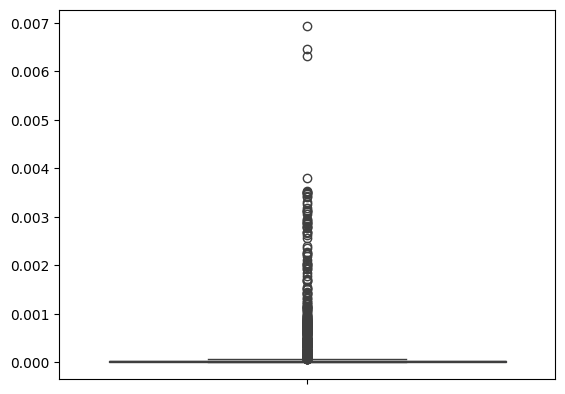

In [31]:
import seaborn as sns

sns.boxplot(data=abs_percentage_errors)

In [30]:
import numpy as np

def remove_outliers_iqr(data):
    Q1 = np.percentile(data, 25)
    Q3 = np.percentile(data, 75)
    IQR = Q3 - Q1
    
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    mask = (data >= lower_bound) & (data <= upper_bound)
    
    num_outliers = np.sum(~mask)  # Count outliers
    filtered_data = data[mask]  # Remove outliers

    return num_outliers, filtered_data, mask

# Example usage:
# data = np.array([10, 12, 15, 18, 100, 105, 14, 17, 19, 13])
num_outliers, filtered_data, mask = remove_outliers_iqr(abs_percentage_errors)
print("Number of outliers:", num_outliers)
print("Filtered data:", filtered_data)


Number of outliers: 284
Filtered data: [2.65799538e-05 2.31433616e-05 1.70679748e-05 ... 9.22739059e-06
 9.05846332e-06 8.73621862e-06]


<Axes: >

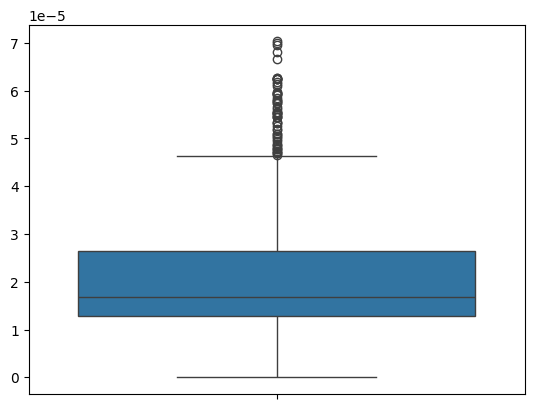

In [32]:
sns.boxplot(data=filtered_data)

284


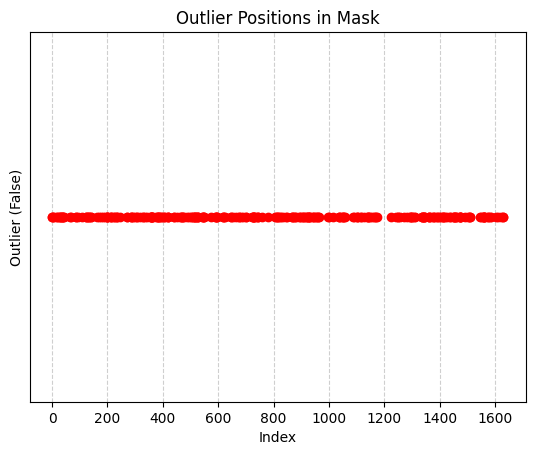

In [36]:
import numpy as np
import matplotlib.pyplot as plt

def plot_mask(mask):
    false_indices = np.where(~mask)[0]  # Get indices where mask is False
    
    print(len(false_indices))
    
    plt.plot(false_indices, np.zeros_like(false_indices), 'ro', markersize=6)  # Red dots for False values
    plt.xlabel("Index")
    plt.ylabel("Outlier (False)")
    plt.title("Outlier Positions in Mask")
    plt.yticks([])  # Hide y-axis ticks
    plt.grid(axis='x', linestyle='--', alpha=0.6)
    plt.show()
    
plot_mask(mask)

In [21]:
abs_percentage_errors[2]

np.float64(0.0043278936482307635)

In [15]:
print(len(abs_percentage_errors))

1637


In [7]:
directions_reshaped

array([[ 0.04276995,  0.        ,  0.        , ...,  0.        ,
         0.        ,  0.        ],
       [ 0.08553989,  0.        ,  0.        , ...,  0.        ,
         0.        ,  0.        ],
       [ 0.08553989,  0.        ,  0.        , ...,  0.        ,
         0.        ,  0.        ],
       ...,
       [-0.04276995,  0.        ,  0.        , ...,  0.        ,
         0.        ,  0.        ],
       [-0.04276995,  0.        ,  0.        , ...,  0.        ,
         0.        ,  0.        ],
       [ 0.04276995,  0.        ,  0.        , ...,  0.        ,
         0.        ,  0.        ]], shape=(3274, 7))